# E3 · Modelado predictivo de riesgo crediticio

## Objetivo y contexto
Construir y comparar dos árboles de decisión para identificar clientes con riesgo de impago. `Riesgo_Impago = 1` representa impago y `0` cumplimiento. Bajo la política simplificada del ejercicio, se concede crédito a quienes se predicen como cumplidores.

El enunciado asigna **$1.500.000 por falso negativo** (crédito otorgado que termina en impago) y **$200.000 por falso positivo** (crédito viable denegado). Por tanto, un FN cuesta 7,5 veces un FP. Se usan esos importes tal como se entregan, sin convertir moneda ni equipararlos al monto individual de cada préstamo.

**Reproducibilidad:** el CSV original está incorporado en este notebook. Ejecutar todas las celdas en orden; no se requiere subir archivos ni descargar datos. La celda de datos contiene el CSV comprimido y verifica su integridad antes de cargarlo. Dependencias: pandas, numpy, matplotlib, scikit-learn e IPython. La semilla de los procedimientos aleatorios es 29. Las versiones utilizadas se muestran a continuación.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay, make_scorer

RANDOM_STATE = 29
TARGET = 'Riesgo_Impago'
FEATURES = ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']
COSTO_FN, COSTO_FP = 1_500_000, 200_000
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| numpy:', np.__version__)
print('scikit-learn:', sklearn.__version__, '| matplotlib:', matplotlib.__version__)


Python: 3.14.0
pandas: 3.1.0 | numpy: 2.5.4
scikit-learn: 1.9.1 | matplotlib: 3.11.2


## 1. Diagnóstico y calidad de datos (EDA)
Se revisan estructura, tipos, nulos, duplicados, reglas de dominio, extremos y distribución del objetivo. Esta inspección describe el archivo; las transformaciones que aprenden parámetros se ajustan después exclusivamente con entrenamiento. No se usan asociaciones con el target del test para seleccionar variables.


In [ ]:
#@title Carga automática de datos
import base64
import gzip
import hashlib
from io import BytesIO

CSV_COMPRIMIDO = '...'
csv_bytes = gzip.decompress(base64.b64decode(CSV_COMPRIMIDO))
assert hashlib.sha256(csv_bytes).hexdigest() == '914de8e6f25d4d64738ad9e1ea1730e7d618940ea6650ef71f66868b30bca844', 'Los datos integrados no coinciden con el archivo original.'
raw = pd.read_csv(BytesIO(csv_bytes))


In [2]:
assert set(FEATURES + [TARGET]).issubset(raw.columns), 'Faltan columnas requeridas.'
print('Dimensiones originales:', raw.shape)
display(raw.head())
raw.info()
display(raw.describe().T)
display(pd.DataFrame({'tipo': raw.dtypes.astype(str), 'nulos': raw.isna().sum(),
                      'nulos_%': raw.isna().mean()*100}))

if 'Unnamed: 0' in raw:
    assert np.array_equal(raw['Unnamed: 0'].to_numpy(), np.arange(len(raw)))
df = raw[FEATURES + [TARGET]].copy()
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in df)
assert df[TARGET].notna().all() and set(df[TARGET].unique()) == {0, 1}
print('Duplicados sin índice:', df.duplicated().sum())
print('Predictores idénticos:', df.duplicated(subset=FEATURES).sum())

reglas = pd.Series({
    'Ingreso no positivo': (df.Ingreso_Anual <= 0).sum(),
    'Préstamo no positivo': (df.Monto_Prestamo <= 0).sum(),
    'Puntaje fuera de 300–850': (~df.Puntaje_Credito.between(300, 850)).sum(),
    'DTI fuera de 0–100 %': (~df.Relacion_Deuda_Ingreso.between(0, 100)).sum(),
    'Valores infinitos': np.isinf(df[FEATURES].to_numpy()).sum()
}, name='casos')
display(reglas.to_frame())
assert reglas.sum() == 0, 'Revisar nuevas inconsistencias antes de entrenar.'
assert df.duplicated(subset=FEATURES).sum() == 0, 'Revisar duplicados antes del split.'


Dimensiones originales: (25000, 6)


,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,39785.55,85246.38,694.0,70.00,0
1,1,69773.95,244260.00,622.0,10.65,0
2,2,127770.68,209310.35,780.0,42.70,0
3,3,16799.80,213059.98,741.0,48.04,0
4,4,70229.83,219523.13,714.0,25.58,0


<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,25000.0,12499.500000,7217.022701,0.00,6249.7500,12499.500,18749.2500,24999.00
Ingreso_Anual,25000.0,55824.444883,29804.903177,7832.12,35051.3175,49234.685,68923.5200,348135.55
Monto_Prestamo,25000.0,220162.891849,60059.302633,50000.00,179438.0775,220241.470,261003.3625,451784.21
Puntaje_Credito,25000.0,680.033440,59.784266,457.00,640.0000,680.000,721.0000,850.00
Relacion_Deuda_Ingreso,25000.0,24.027319,13.615029,5.00,13.7875,21.450,31.3825,70.00
Riesgo_Impago,25000.0,0.071560,0.257763,0.00,0.0000,0.000,0.0000,1.00


,tipo,nulos,nulos_%
Unnamed: 0,int64,0,0.0
Ingreso_Anual,float64,0,0.0
Monto_Prestamo,float64,0,0.0
Puntaje_Credito,float64,0,0.0
Relacion_Deuda_Ingreso,float64,0,0.0
Riesgo_Impago,int64,0,0.0


Duplicados sin índice: 0
Predictores idénticos: 0


,casos
Ingreso no positivo,0
Préstamo no positivo,0
Puntaje fuera de 300–850,0
DTI fuera de 0–100 %,0
Valores infinitos,0


,cantidad,porcentaje
Cumplimiento (0),23211,92.844
Impago (1),1789,7.156


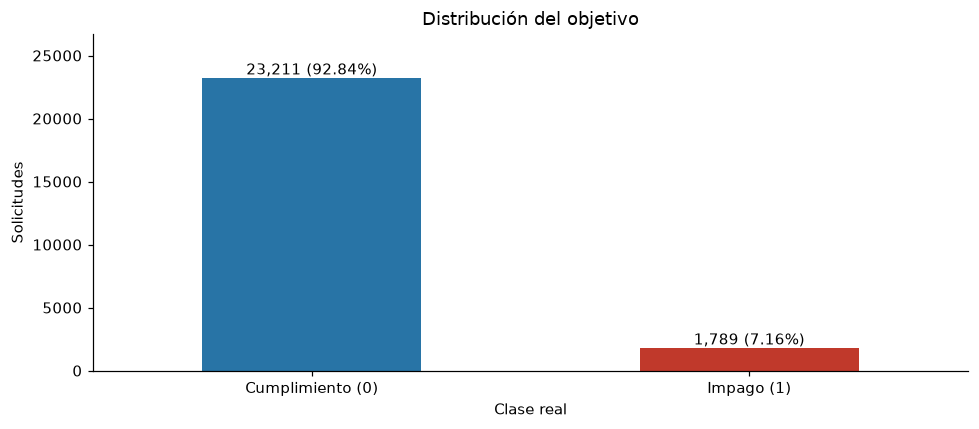

**Desbalance:** 1,789 impagos de 25,000 solicitudes (7.16%). Predecir siempre cumplimiento acertaría 92.84%, pero detectaría cero impagos. Por eso la exactitud no será una de las dos métricas principales.

In [3]:
balance = df[TARGET].value_counts().sort_index().rename('cantidad').to_frame()
balance['porcentaje'] = balance['cantidad'] / len(df) * 100
balance.index = ['Cumplimiento (0)', 'Impago (1)']
display(balance)
ax = balance['cantidad'].plot.bar(color=['#2874A6', '#C0392B'], rot=0)
ax.set(title='Distribución del objetivo', ylabel='Solicitudes', xlabel='Clase real')
for i, n in enumerate(balance['cantidad']):
    ax.text(i, n, f'{n:,} ({balance.iloc[i, 1]:.2f}%)', ha='center', va='bottom')
ax.set_ylim(0, balance['cantidad'].max()*1.15)
plt.tight_layout(); plt.show()
display(Markdown(f'**Desbalance:** {df[TARGET].sum():,} impagos de {len(df):,} solicitudes '
                 f'({df[TARGET].mean():.2%}). Predecir siempre cumplimiento acertaría '
                 f'{1-df[TARGET].mean():.2%}, pero detectaría cero impagos. Por eso la exactitud '
                 'no será una de las dos métricas principales.'))


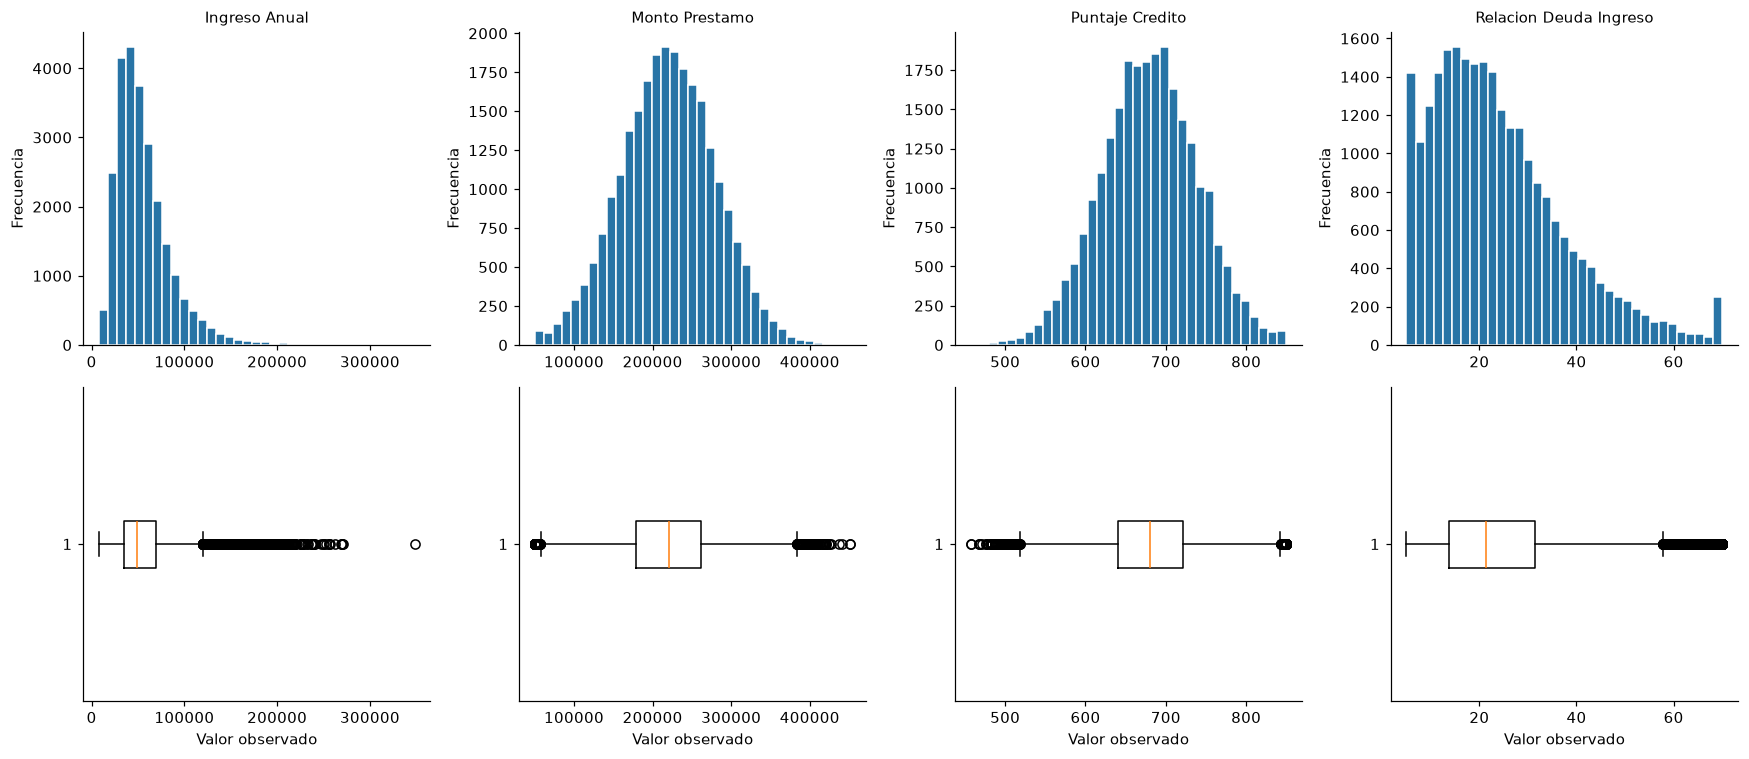

,Variable,Límite IQR inferior,Límite IQR superior,Extremos IQR,Porcentaje
0,Ingreso_Anual,-15756.99,119731.82,976,3.90
1,Monto_Prestamo,57090.15,383351.29,157,0.63
2,Puntaje_Credito,518.50,842.50,167,0.67
3,Relacion_Deuda_Ingreso,-12.60,57.78,663,2.65


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
extremos = []
for i, col in enumerate(FEATURES):
    s = df[col]
    q1, q3 = s.quantile([.25, .75]); iqr = q3-q1
    inferior, superior = q1-1.5*iqr, q3+1.5*iqr
    n = ((s<inferior) | (s>superior)).sum()
    extremos.append([col, inferior, superior, n, n/len(df)*100])
    axes[0,i].hist(s, bins=35, color='#2874A6', edgecolor='white')
    axes[0,i].set_title(col.replace('_',' '), fontsize=10)
    axes[0,i].set_ylabel('Frecuencia')
    axes[1,i].boxplot(s, orientation='horizontal')
    axes[1,i].set_xlabel('Valor observado')
plt.tight_layout(); plt.show()
display(pd.DataFrame(extremos, columns=['Variable','Límite IQR inferior','Límite IQR superior',
                                       'Extremos IQR','Porcentaje']).round(2))


### Interpretación y decisiones de calidad
- El archivo contiene 25.000 observaciones, cuatro predictores numéricos y un objetivo binario. `Unnamed: 0` es un índice de exportación consecutivo, sin significado financiero, y se excluye.
- No se detectan nulos, infinitos, duplicados ni incumplimientos de las reglas verificadas. Se conservan todas las observaciones.
- El ingreso presenta una cola derecha marcada. Los límites IQR identifican extremos estadísticos, no errores demostrados. Se conservan: un ingreso elevado o un préstamo grande puede ser legítimo. Recortarlos sin evidencia podría borrar casos financieros relevantes.
- La relación deuda/ingreso se interpreta en puntos porcentuales conforme al diccionario: sus valores observados van de 5 a 70. El rango 0–100 % se utiliza como control de calidad para este conjunto.
- El desbalance implica que los aciertos sobre clientes cumplidores pueden ocultar impagos no detectados. Se estratifica la división y se usan métricas centradas en la clase 1.

## 2. Separación y pipeline de tratamiento
Se reserva **20 % para prueba**, con estratificación y semilla 29. El 80 % restante se utiliza en toda la búsqueda. La imputación por mediana se incluye como tratamiento reproducible de futuros nulos; en este archivo no modifica observaciones. No se aplica escalado porque el árbol trabaja mediante umbrales. Tampoco se necesita codificación categórica.

`ColumnTransformer` selecciona los cuatro predictores y `Pipeline` integra imputación y clasificador. En validación cruzada, las medianas se aprenden únicamente en la partición de entrenamiento de cada fold. No se aplica sobremuestreo ni ajuste de umbral sobre el test.


In [5]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train)+len(X_test) == len(df)
display(pd.DataFrame({'n': [len(y_train),len(y_test)],
                      'impagos': [int(y_train.sum()),int(y_test.sum())],
                      'impago_%': [y_train.mean()*100,y_test.mean()*100]},
                     index=['Entrenamiento','Prueba']))

def crear_pipeline():
    preprocesamiento = ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), FEATURES)
    ], remainder='drop')
    return Pipeline([('preprocesamiento', preprocesamiento),
                     ('arbol', DecisionTreeClassifier(random_state=RANDOM_STATE))])

base = crear_pipeline()
base.fit(X_train, y_train)
print('Línea base: árbol por defecto, salvo random_state=29.')


,n,impagos,impago_%
Entrenamiento,20000,1431,7.155
Prueba,5000,358,7.160


Línea base: árbol por defecto, salvo random_state=29.


## 3. Optimización del árbol
Se exploran **cinco hiperparámetros**: `criterion` (Gini/entropía), `max_depth` (complejidad), `min_samples_split` (mínimo para dividir), `min_samples_leaf` (estabilidad de las hojas) y `class_weight` (atención al impago minoritario).

Se evalúan 60 combinaciones reproducibles mediante `RandomizedSearchCV` con cinco particiones estratificadas. El criterio de selección es minimizar el costo medio de errores en validación: `(1.500.000 FN + 200.000 FP) / n`. Su versión negativa se maximiza en Scikit-Learn. La ponderación 7,5:1 refleja la relación de costos como candidato, sin asumir que será la mejor.

Este criterio evita escoger un modelo solo por un recall alto obtenido a costa de rechazar casi todos los créditos. Las métricas principales de reporte son **Recall y Precision**; el costo es un indicador de negocio complementario y el objetivo de optimización. El test permanece reservado.


In [6]:
def costo_medio(y_real, y_pred):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0,1]).ravel()
    return (COSTO_FN*fn + COSTO_FP*fp)/len(y_real)

scoring_costo = make_scorer(costo_medio, greater_is_better=False)
espacio = {
    'arbol__criterion': ['gini', 'entropy'],
    'arbol__max_depth': [3, 5, 7, 10, None],
    'arbol__min_samples_split': [2, 20, 100],
    'arbol__min_samples_leaf': [1, 10, 50, 100],
    'arbol__class_weight': [None, 'balanced', {0:1, 1:7.5}]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
busqueda = RandomizedSearchCV(
    crear_pipeline(), param_distributions=espacio, n_iter=60,
    scoring={'costo': scoring_costo, 'recall': 'recall', 'precision': make_scorer(precision_score, zero_division=0)},
    refit='costo', cv=cv, random_state=RANDOM_STATE, n_jobs=1,
    return_train_score=True, error_score='raise')
busqueda.fit(X_train, y_train)
optimizado = busqueda.best_estimator_
print('Mejores hiperparámetros:', busqueda.best_params_)
print(f'Costo medio de validación seleccionado: ${-busqueda.best_score_:,.2f}')
cv_resultados = pd.DataFrame(busqueda.cv_results_).sort_values('rank_test_costo')
display(cv_resultados[['rank_test_costo','mean_test_costo','std_test_costo',
                       'mean_test_recall','mean_test_precision','params']].head(5))


Mejores hiperparámetros: {'arbol__min_samples_split': 100, 'arbol__min_samples_leaf': 100, 'arbol__max_depth': 7, 'arbol__criterion': 'entropy', 'arbol__class_weight': {0: 1, 1: 7.5}}
Costo medio de validación seleccionado: $68,355.00


,rank_test_costo,mean_test_costo,std_test_costo,mean_test_recall,mean_test_precision,params
25,1,-68355.0,3588.293466,0.606581,0.251771,"{'arbol__min_samples_split': 100, 'arbol__min_..."
37,2,-68790.0,4037.839769,0.617059,0.242562,"{'arbol__min_samples_split': 2, 'arbol__min_sa..."
24,3,-69090.0,3634.783350,0.596089,0.250407,"{'arbol__min_samples_split': 100, 'arbol__min_..."
43,4,-69475.0,4658.138040,0.610748,0.240697,"{'arbol__min_samples_split': 20, 'arbol__min_s..."
9,5,-69950.0,2431.049156,0.587710,0.247021,"{'arbol__min_samples_split': 20, 'arbol__min_s..."


## 4. Evaluación final sobre el conjunto de prueba
Las **dos métricas principales** se calculan para impago = 1:

1. **Recall = VP / (VP + FN)**: proporción de impagos reales detectados. Un recall bajo deja pasar créditos que pueden generar pérdidas de capital.
2. **Precision = VP / (VP + FP)**: proporción de alertas de riesgo que corresponden a impagos reales. Una precisión baja implica denegar demasiados créditos viables.

Ambas son necesarias para interpretar el equilibrio entre pérdidas directas y oportunidades perdidas. Si no hay predicciones positivas, se reporta precisión 0 mediante `zero_division=0`. El costo total complementa las métricas y usa el mismo tamaño de test para ambos modelos.


In [7]:
def evaluar(nombre, modelo, X_eval, y_eval):
    pred = modelo.predict(X_eval)
    vn, fp, fn, vp = confusion_matrix(y_eval,pred,labels=[0,1]).ravel()
    return {'Modelo':nombre, 'Recall':recall_score(y_eval,pred,zero_division=0),
            'Precision':precision_score(y_eval,pred,zero_division=0),
            'VN':int(vn),'FP':int(fp),'FN':int(fn),'VP':int(vp),
            'Costo total':int(COSTO_FN*fn+COSTO_FP*fp),
            'Costo por solicitud':costo_medio(y_eval,pred)}

resultados = pd.DataFrame([evaluar('Línea base',base,X_test,y_test),
                           evaluar('Optimizado',optimizado,X_test,y_test)]).set_index('Modelo')
display(resultados.round(4))
for _, r in resultados.iterrows():
    assert r[['VN','FP','FN','VP']].sum() == len(y_test)
    assert r['VP']+r['FN'] == y_test.sum()
    assert r['Costo total'] == COSTO_FN*r['FN']+COSTO_FP*r['FP']

diagnostico_ajuste = []
for nombre, modelo in [('Línea base',base),('Optimizado',optimizado)]:
    for conjunto, xx, yy in [('Train',X_train,y_train),('Test',X_test,y_test)]:
        fila = evaluar(nombre,modelo,xx,yy); fila['Conjunto']=conjunto
        diagnostico_ajuste.append(fila)
display(pd.DataFrame(diagnostico_ajuste)[['Modelo','Conjunto','Recall','Precision','Costo por solicitud']])
print('Referencia de negocio: conceder todos los créditos costaría',
      f'${int(y_test.sum()*COSTO_FN):,} en este test.')


,Recall,Precision,VN,FP,FN,VP,Costo total,Costo por solicitud
Modelo,,,,,,,,
Línea base,0.3156,0.2875,4362,280,245,113,423500000,84700.0
Optimizado,0.6648,0.2662,3986,656,120,238,311200000,62240.0


,Modelo,Conjunto,Recall,Precision,Costo por solicitud
0,Línea base,Train,1.000000,1.000000,0.0
1,Línea base,Test,0.315642,0.287532,84700.0
2,Optimizado,Train,0.677848,0.268401,61015.0
3,Optimizado,Test,0.664804,0.266219,62240.0


Referencia de negocio: conceder todos los créditos costaría $537,000,000 en este test.


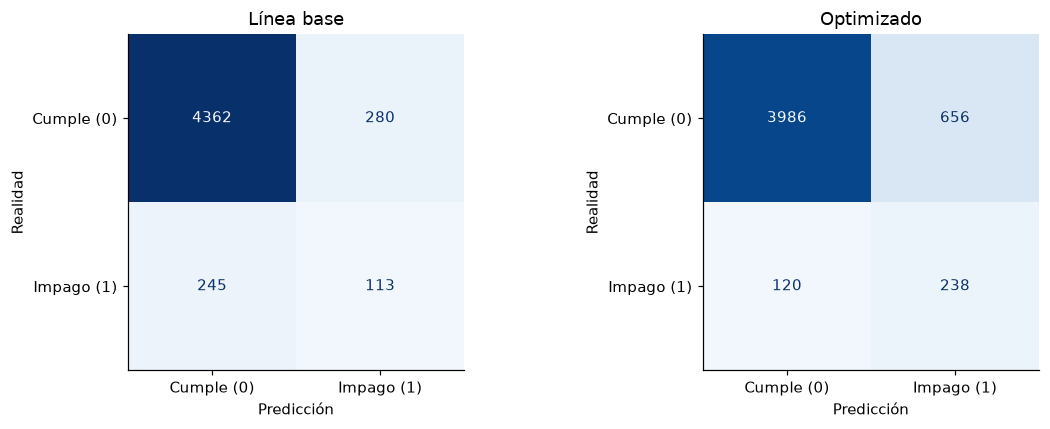

### Línea base: interpretación financiera
- **VN = 4,362:** clientes cumplidores correctamente identificados.
- **VP = 113:** impagos detectados; bajo la política del ejercicio se evita otorgar esos créditos.
- **FP = 280:** créditos viables denegados; costo de oportunidad **$56,000,000**.
- **FN = 245:** impagos no detectados; pérdida directa estimada **$367,500,000**.
- El modelo detecta **31.56%** de los impagos; **28.75%** de sus alertas corresponden a impagos reales. El costo agregado de errores es **$423,500,000**.


### Optimizado: interpretación financiera
- **VN = 3,986:** clientes cumplidores correctamente identificados.
- **VP = 238:** impagos detectados; bajo la política del ejercicio se evita otorgar esos créditos.
- **FP = 656:** créditos viables denegados; costo de oportunidad **$131,200,000**.
- **FN = 120:** impagos no detectados; pérdida directa estimada **$180,000,000**.
- El modelo detecta **66.48%** de los impagos; **26.62%** de sus alertas corresponden a impagos reales. El costo agregado de errores es **$311,200,000**.


### Comparación
El optimizado cambia los FN de **245 a 120** y los FP de **280 a 656**.
El cambio en recall es **+34.92 puntos porcentuales** y en precisión **-2.13 puntos**.
La diferencia de costo (base menos optimizado) es **$112,300,000**: un valor positivo significa ahorro estimado con el optimizado.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
matrices = [confusion_matrix(y_test,m.predict(X_test),labels=[0,1]) for m in [base,optimizado]]
maximo = max(cm.max() for cm in matrices)
for ax, cm, titulo in zip(axes, matrices, ['Línea base','Optimizado']):
    ConfusionMatrixDisplay(cm, display_labels=['Cumple (0)','Impago (1)']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d', im_kw={'vmin':0,'vmax':maximo})
    ax.set(title=titulo, xlabel='Predicción', ylabel='Realidad')
plt.tight_layout(); plt.show()

for nombre,r in resultados.iterrows():
    display(Markdown(f"""### {nombre}: interpretación financiera
- **VN = {int(r.VN):,}:** clientes cumplidores correctamente identificados.
- **VP = {int(r.VP):,}:** impagos detectados; bajo la política del ejercicio se evita otorgar esos créditos.
- **FP = {int(r.FP):,}:** créditos viables denegados; costo de oportunidad **${int(r.FP*COSTO_FP):,}**.
- **FN = {int(r.FN):,}:** impagos no detectados; pérdida directa estimada **${int(r.FN*COSTO_FN):,}**.
- El modelo detecta **{r.Recall:.2%}** de los impagos; **{r.Precision:.2%}** de sus alertas corresponden a impagos reales. El costo agregado de errores es **${int(r['Costo total']):,}**.
"""))
b,o = resultados.loc['Línea base'], resultados.loc['Optimizado']
diferencia = b['Costo total']-o['Costo total']
display(Markdown(f"""### Comparación
El optimizado cambia los FN de **{int(b.FN)} a {int(o.FN)}** y los FP de **{int(b.FP)} a {int(o.FP)}**.
El cambio en recall es **{(o.Recall-b.Recall)*100:+.2f} puntos porcentuales** y en precisión **{(o.Precision-b.Precision)*100:+.2f} puntos**.
La diferencia de costo (base menos optimizado) es **${diferencia:,.0f}**: un valor positivo significa ahorro estimado con el optimizado.
"""))


## 5. Interpretabilidad del modelo optimizado
Las importancias muestran qué variables reducen más impureza en este árbol. No son efectos causales ni justifican por sí mismas decisiones crediticias individuales. La figura muestra solamente los primeros tres niveles para facilitar la lectura; no representa el árbol completo si su profundidad es mayor.


**Sobreajuste observado:** la línea base obtiene Recall y Precision de 100 % en entrenamiento, pero solo 31,56 % y 28,75 % en prueba. El optimizado obtiene 67,78 % y 26,84 % en entrenamiento, frente a 66,48 % y 26,62 % en prueba: una brecha mucho menor. La restricción de profundidad y el mínimo de 100 observaciones por hoja reducen la complejidad.

**Lectura del árbol:** `samples` representa observaciones; `value` refleja los pesos de clase usados en el entrenamiento y no debe leerse como conteo bruto de clientes cuando `class_weight` está activo.


Profundidad final:

 7 | Hojas: 65


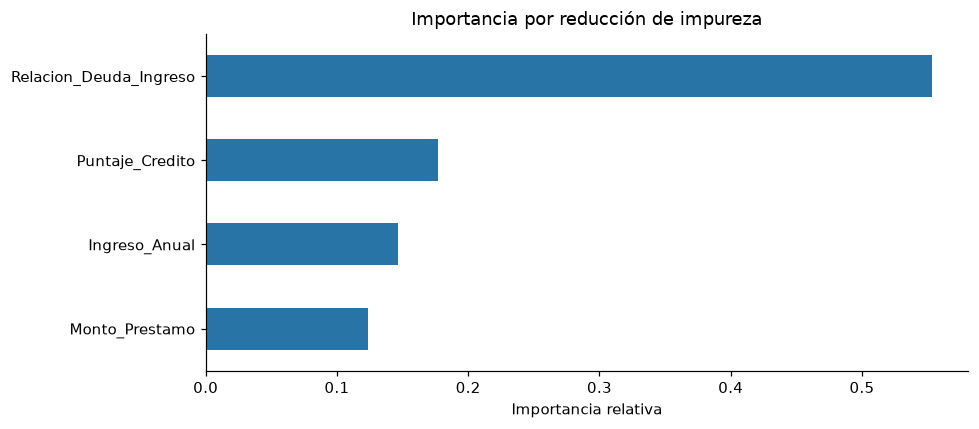

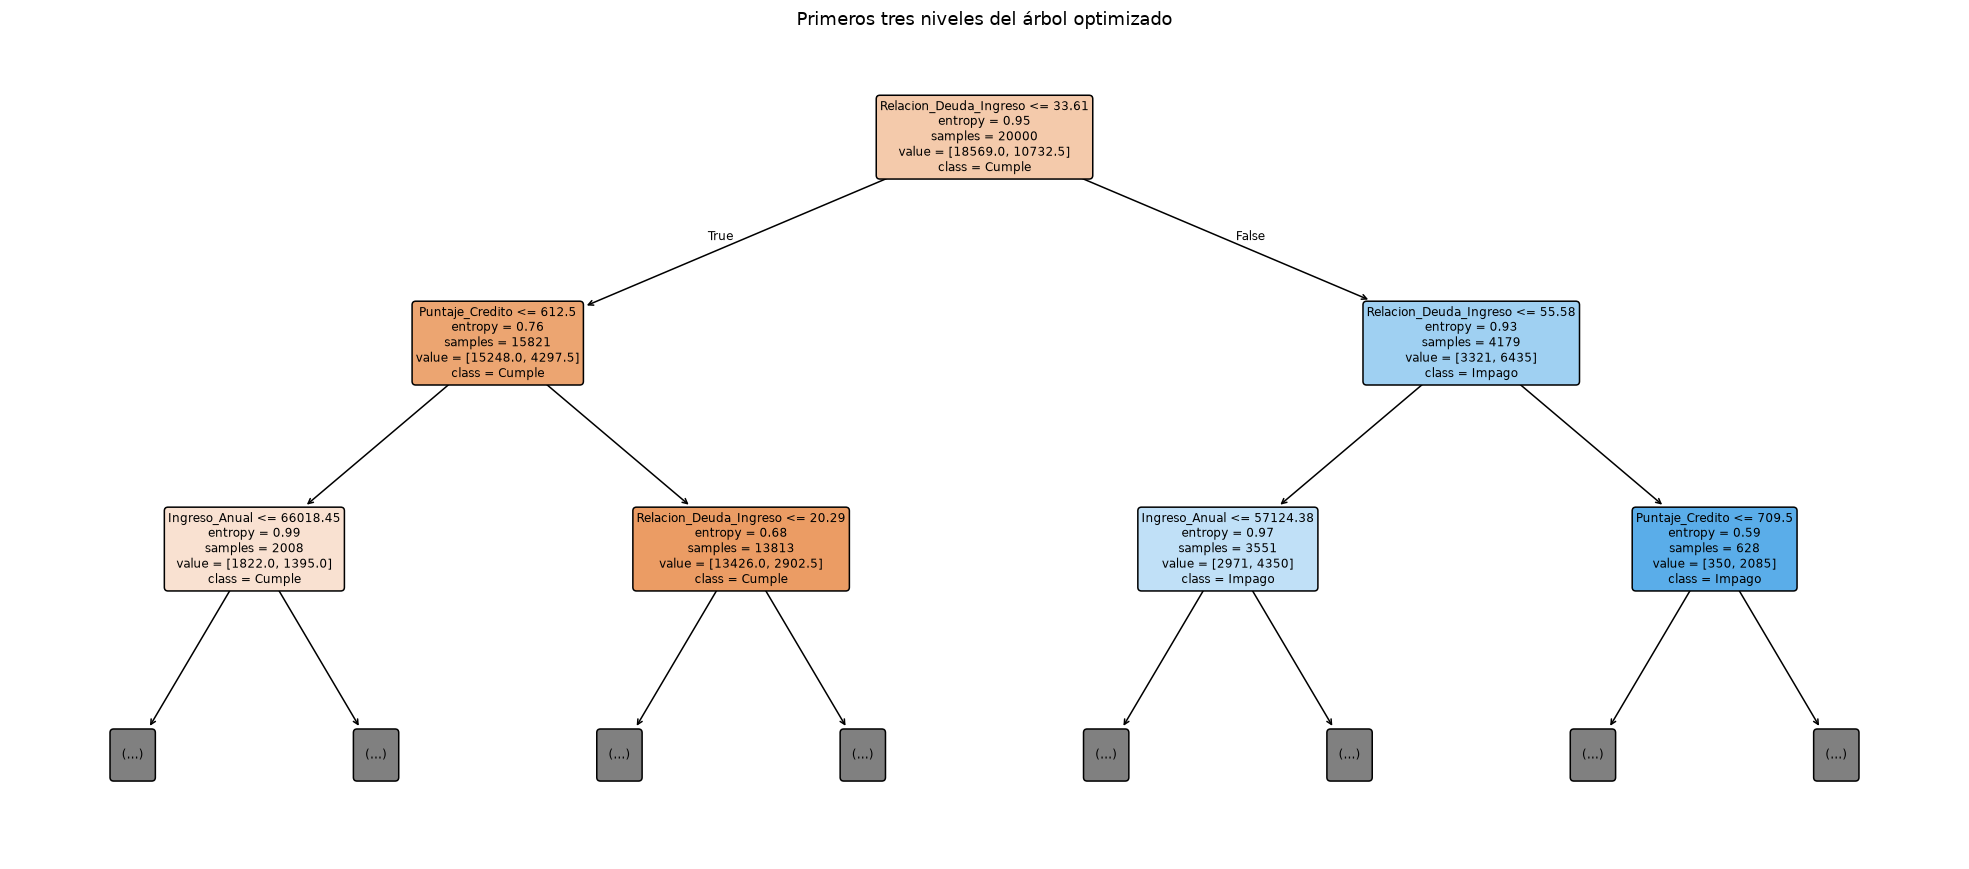

In [9]:
arbol = optimizado.named_steps['arbol']
print('Profundidad final:', arbol.get_depth(), '| Hojas:', arbol.get_n_leaves())
importancias = pd.Series(arbol.feature_importances_,index=FEATURES).sort_values()
importancias.plot.barh(color='#2874A6', title='Importancia por reducción de impureza')
plt.xlabel('Importancia relativa'); plt.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(18,8))
plot_tree(arbol,feature_names=FEATURES,class_names=['Cumple','Impago'],
          max_depth=2,filled=True,rounded=True,precision=2,fontsize=8,ax=ax)
ax.set_title('Primeros tres niveles del árbol optimizado')
plt.tight_layout(); plt.show()


In [10]:
recomendado = 'optimizado' if diferencia > 0 else 'base' if diferencia < 0 else 'cualquiera de los dos por costo (empate)'
display(Markdown(f"""## 6. Conclusión
En esta partición de prueba, el menor costo corresponde al modelo **{recomendado}**.
La selección de hiperparámetros del optimizado se realizó exclusivamente en validación cruzada de entrenamiento; la prueba se utilizó para esta comparación final.
El ahorro estimado del optimizado frente a la base es **${diferencia:,.0f}** para **{len(y_test):,} solicitudes**, bajo los costos y la política simplificada del enunciado.
La recomendación debe leerse junto con el cambio en detección de impagos y falsos rechazos, no solo con una cifra agregada.
"""))


## 6. Conclusión
En esta partición de prueba, el menor costo corresponde al modelo **optimizado**.
La selección de hiperparámetros del optimizado se realizó exclusivamente en validación cruzada de entrenamiento; la prueba se utilizó para esta comparación final.
El ahorro estimado del optimizado frente a la base es **$112,300,000** para **5,000 solicitudes**, bajo los costos y la política simplificada del enunciado.
La recomendación debe leerse junto con el cambio en detección de impagos y falsos rechazos, no solo con una cifra agregada.


**Balance financiero observado:** se evitan 125 falsos negativos, lo que reduce pérdidas estimadas en $187.500.000, a cambio de 376 falsos positivos adicionales que cuestan $75.200.000. La diferencia neta es $112.300.000 (26,52 % menos costo que la base). La precisión de 26,62 % del optimizado significa que aproximadamente tres de cada cuatro alertas son falsos positivos: su ventaja de costo no implica que las alertas sean altamente confiables.

### Limitaciones
Los costos calculados son estimaciones basadas en los importes fijos del enunciado y en una sola partición de prueba. Antes de aplicar el modelo en un banco, se requiere validarlo con nuevos datos.

### Referencias
Material de la asignatura: `620454_Gini_Entropy-2.ipynb`, `Entropy-Gini.pdf`, `Clasificación.pdf`, `Evaluación_de_Modelos_de_Clasificación.pdf` y `MatrizConfusion.jpg`.
